<a href="https://colab.research.google.com/github/Rajak20/Used_Car_Price_Prediction/blob/main/Used_Car_Price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv("used_cars.csv")

In [4]:
df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   brand         4009 non-null   object
 1   model         4009 non-null   object
 2   model_year    4009 non-null   int64 
 3   milage        4009 non-null   object
 4   fuel_type     3839 non-null   object
 5   engine        4009 non-null   object
 6   transmission  4009 non-null   object
 7   ext_col       4009 non-null   object
 8   int_col       4009 non-null   object
 9   accident      3896 non-null   object
 10  clean_title   3413 non-null   object
 11  price         4009 non-null   object
dtypes: int64(1), object(11)
memory usage: 376.0+ KB


In [6]:
df.describe()

,model_year
count,4009.000000
mean,2015.515590
std,6.104816
min,1974.000000
25%,2012.000000
50%,2017.000000
75%,2020.000000
max,2024.000000


In [8]:
df.shape

(4009, 12)

In [9]:
df.columns

Index(['brand', 'model', 'model_year', 'milage', 'fuel_type', 'engine',
       'transmission', 'ext_col', 'int_col', 'accident', 'clean_title',
       'price'],
      dtype='object')

In [10]:
df.isnull().sum()

,0
brand,0
model,0
model_year,0
milage,0
fuel_type,170
engine,0
transmission,0
ext_col,0
int_col,0
accident,113


In [12]:
df['fuel_type'].value_counts()

,count
fuel_type,
Gasoline,3309
Hybrid,194
E85 Flex Fuel,139
Diesel,116
–,45
Plug-In Hybrid,34
not supported,2


In [13]:
df["fuel_type"] = df["fuel_type"].fillna(df["fuel_type"].mode()[0])

In [14]:
df['accident'].value_counts()

,count
accident,
None reported,2910
At least 1 accident or damage reported,986


In [15]:
df["accident"] = df["accident"].fillna(df["accident"].mode()[0])

In [16]:
df['clean_title'].value_counts()

,count
clean_title,
Yes,3413


In [17]:
df['clean_title'] = df['clean_title'].fillna(df['clean_title'].mode()[0])

In [18]:
df.isnull().sum()

,0
brand,0
model,0
model_year,0
milage,0
fuel_type,0
engine,0
transmission,0
ext_col,0
int_col,0
accident,0


In [19]:
df.drop_duplicates(inplace=True)

In [20]:
df.shape

(4009, 12)

In [27]:
# Clean 'price' and 'milage' columns to convert them to numeric values
df['price_clean'] = df['price'].str.replace('$', '').str.replace(',', '').astype(float)
df['milage_clean'] = df['milage'].str.replace(' mi.', '').str.replace(',', '').astype(float)

# Display summary statistics to see the distribution
display(df[['price_clean', 'milage_clean', 'model_year']].describe())

,price_clean,milage_clean,model_year
count,4.009000e+03,4009.000000,4009.000000
mean,4.455319e+04,64717.551010,2015.515590
std,7.871064e+04,52296.599459,6.104816
min,2.000000e+03,100.000000,1974.000000
25%,1.720000e+04,23044.000000,2012.000000
50%,3.100000e+04,52775.000000,2017.000000
75%,4.999000e+04,94100.000000,2020.000000
max,2.954083e+06,405000.000000,2024.000000


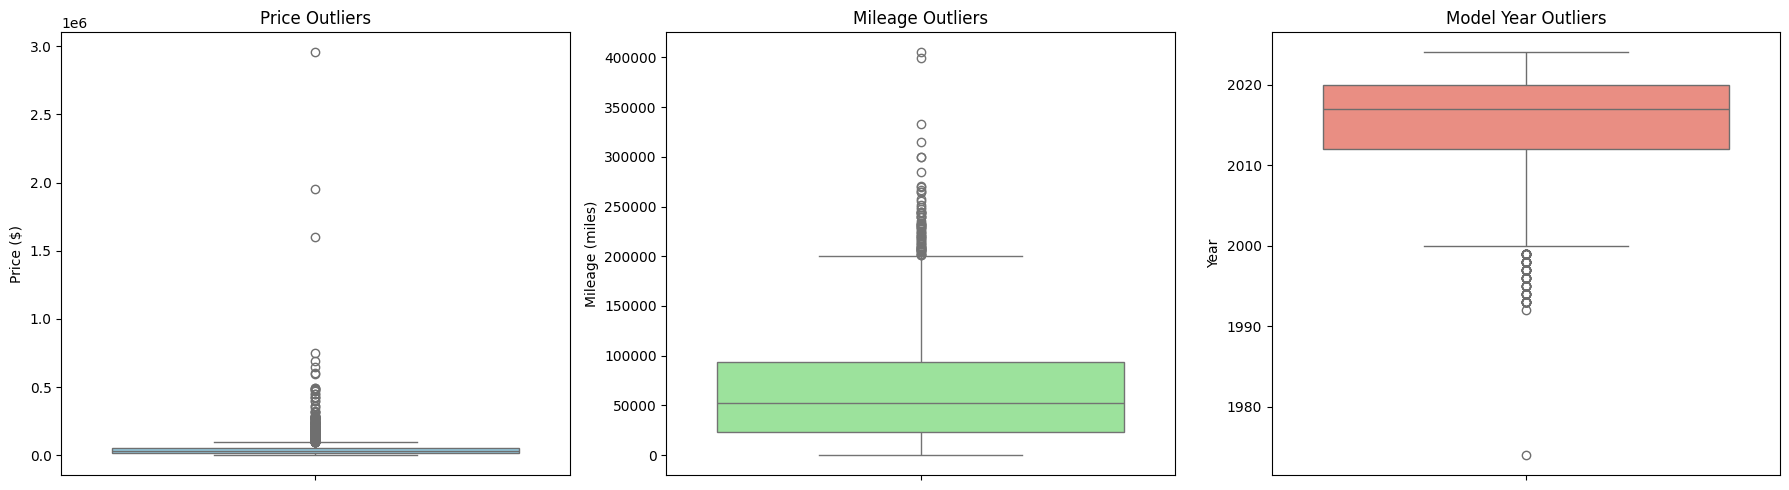

In [28]:
# Visualize distributions with boxplots to identify outliers
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(ax=axes[0], y=df['price_clean'], color='skyblue')
axes[0].set_title('Price Outliers')
axes[0].set_ylabel('Price ($)')

sns.boxplot(ax=axes[1], y=df['milage_clean'], color='lightgreen')
axes[1].set_title('Mileage Outliers')
axes[1].set_ylabel('Mileage (miles)')

sns.boxplot(ax=axes[2], y=df['model_year'], color='salmon')
axes[2].set_title('Model Year Outliers')
axes[2].set_ylabel('Year')

plt.tight_layout()
plt.show()

In [29]:
# Identify all original string (object) columns
string_cols = df.select_dtypes(include=['object']).columns.tolist()

# Remove 'milage' and 'price' as they are the uncleaned numerical raw inputs
for col in ['price', 'milage']:
    if col in string_cols:
        string_cols.remove(col)

print("Categorical columns to One-Hot Encode:", string_cols)

# Perform One-Hot Encoding using pandas
df_encoded = pd.get_dummies(df, columns=string_cols, drop_first=True)

# Display the new shape and head of the encoded DataFrame
print("New shape of encoded DataFrame:", df_encoded.shape)
display(df_encoded.head())

Categorical columns to One-Hot Encode: ['brand', 'model', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title']
New shape of encoded DataFrame: (4009, 3644)


,model_year,milage,price,price_clean,milage_clean,brand_Alfa,brand_Aston,brand_Audi,brand_BMW,brand_Bentley,...,int_col_Tupelo,int_col_Very Light Cashmere,int_col_WHITE,int_col_Walnut,int_col_Whisper Beige,int_col_White,int_col_White / Brown,int_col_Yellow,int_col_–,accident_None reported
0,2013,"51,000 mi.","$10,300",10300.0,51000.0,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,2021,"34,742 mi.","$38,005",38005.0,34742.0,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,2022,"22,372 mi.","$54,598",54598.0,22372.0,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
3,2015,"88,900 mi.","$15,500",15500.0,88900.0,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
4,2021,"9,835 mi.","$34,999",34999.0,9835.0,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,True


In [30]:
df = df.astype(int)

ValueError: invalid literal for int() with base 10: 'Ford'

In [31]:
# Drop the raw string-based 'price' and 'milage' columns since we have 'price_clean' and 'milage_clean'
if 'price' in df_encoded.columns:
    df_encoded = df_encoded.drop(columns=['price'])
if 'milage' in df_encoded.columns:
    df_encoded = df_encoded.drop(columns=['milage'])

# Convert all boolean columns (True/False) resulting from One-Hot Encoding into integers (1/0)
df_encoded = df_encoded.astype(int)

# Display the top rows of the fully numeric integer/float dataset
display(df_encoded.head())

,model_year,price_clean,milage_clean,brand_Alfa,brand_Aston,brand_Audi,brand_BMW,brand_Bentley,brand_Bugatti,brand_Buick,...,int_col_Tupelo,int_col_Very Light Cashmere,int_col_WHITE,int_col_Walnut,int_col_Whisper Beige,int_col_White,int_col_White / Brown,int_col_Yellow,int_col_–,accident_None reported
0,2013,10300,51000,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2021,38005,34742,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2022,54598,22372,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
3,2015,15500,88900,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
4,2021,34999,9835,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1


In [32]:
from sklearn.model_selection import train_test_split
x = df_encoded.drop(columns=['price_clean'])
y = df_encoded['price_clean']
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=42)

In [34]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.fit_transform(X_test)

In [37]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
lr = LinearRegression()
lr.fit(X_train,y_train)

LinearRegression()

In [38]:
y_pred = lr.predict(X_test)

In [39]:
r2_score(y_test,y_pred)

0.052933778786033114

In [40]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# 1. Apply log transformation to the target variable
y_log = np.log1p(df_encoded['price_clean'])

# 2. Split the dataset (using same features 'x' and new log target 'y_log')
X_train, X_test, y_train_log, y_test_log = train_test_split(x, y_log, test_size=0.20, random_state=42)

# 3. Scale correctly (fit on Train, transform on both Train and Test)
sc = StandardScaler()
X_train_scaled = sc.fit_transform(X_train)
X_test_scaled = sc.transform(X_test)

# 4. Fit the model on log target
lr_log = LinearRegression()
lr_log.fit(X_train_scaled, y_train_log)

# 5. Predict and evaluate
y_pred_log = lr_log.predict(X_test_scaled)

# R2 score on the log scale
r2_log = r2_score(y_test_log, y_pred_log)
print(f"R2 score on log-transformed price: {r2_log:.4f}")

R2 score on log-transformed price: 0.7019


In [41]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
import numpy as np

# Initialize Random Forest Regressor
# We use a reasonable number of estimators and depth to balance accuracy and execution time
rf_model = RandomForestRegressor(n_estimators=150, max_depth=20, random_state=42, n_jobs=-1)

# Fit the model on our scaled training features and log-transformed target
rf_model.fit(X_train_scaled, y_train_log)

# Predict on scaled test features
y_pred_rf_log = rf_model.predict(X_test_scaled)

# Calculate the R2 score on the log scale
rf_r2_log = r2_score(y_test_log, y_pred_rf_log)
print(f"Random Forest R2 Score on log target: {rf_r2_log:.4f}")

Random Forest R2 Score on log target: 0.7186


In [42]:
!pip install -q lightgbm
import lightgbm as lgb
from sklearn.metrics import r2_score

# Initialize LightGBM Regressor with optimized parameters for complex high-dimensional datasets
lgb_model = lgb.LGBMRegressor(
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=63,
    random_state=42,
    n_jobs=-1
)

# Fit on training data with log target
lgb_model.fit(X_train_scaled, y_train_log)

# Predict and evaluate
y_pred_lgb_log = lgb_model.predict(X_test_scaled)
lgb_r2_log = r2_score(y_test_log, y_pred_lgb_log)
print(f"LightGBM R2 Score on log target: {lgb_r2_log:.4f}")

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002241 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 567
[LightGBM] [Info] Number of data points in the train set: 3207, number of used features: 95
[LightGBM] [Info] Start training from score 10.303453
LightGBM R2 Score on log target: 0.6782


In [43]:
!pip install -q category_encoders xgboost
import category_encoders as ce
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
import numpy as np

# 1. Identify raw categorical columns again
categorical_cols = ['brand', 'model', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title']

# 2. Re-split using the cleaned numeric columns to avoid target leakage during target encoding
X_raw = df[['model_year', 'milage_clean'] + categorical_cols]
y_raw_log = np.log1p(df['price_clean'])

X_train_raw, X_test_raw, y_train_log2, y_test_log2 = train_test_split(X_raw, y_raw_log, test_size=0.20, random_state=42)

# 3. Apply Target Encoding (this maps categories to the mean of the log price target, preventing sparse dimension explosion)
encoder = ce.TargetEncoder(cols=categorical_cols, smoothing=10)
X_train_encoded = encoder.fit_transform(X_train_raw, y_train_log2)
X_test_encoded = encoder.transform(X_test_raw)

# 4. Train an optimized XGBoost model
xgb_model = xgb.XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_encoded, y_train_log2)

# 5. Evaluate results
y_pred_xgb = xgb_model.predict(X_test_encoded)
xgb_r2 = r2_score(y_test_log2, y_pred_xgb)
print(f"XGBoost R2 Score with Target Encoding: {xgb_r2:.4f}")

XGBoost R2 Score with Target Encoding: 0.5899


In [44]:
!pip install -q catboost
from catboost import CatBoostRegressor
from sklearn.metrics import r2_score
import numpy as np

# Prepare features (using the raw categories directly since CatBoost handles them natively)
# Fill missing values with a placeholder category
X_raw_cat = X_raw.copy()
for col in categorical_cols:
    X_raw_cat[col] = X_raw_cat[col].fillna('missing').astype(str)

# Split
X_train_cb, X_test_cb, y_train_cb, y_test_cb = train_test_split(
    X_raw_cat, y_raw_log, test_size=0.20, random_state=42
)

# Identify categorical feature indices for CatBoost
cat_features_indices = [X_raw_cat.columns.get_loc(col) for col in categorical_cols]

# Train CatBoost Regressor
cb_model = CatBoostRegressor(
    iterations=1500,
    learning_rate=0.05,
    depth=6,
    eval_metric='R2',
    random_seed=42,
    verbose=100
)

cb_model.fit(
    X_train_cb, y_train_cb,
    cat_features=cat_features_indices,
    eval_set=(X_test_cb, y_test_cb),
    early_stopping_rounds=100
)

# Evaluate
y_pred_cb = cb_model.predict(X_test_cb)
cb_r2 = r2_score(y_test_cb, y_pred_cb)
print(f"\nCatBoost R2 Score with native categorical support: {cb_r2:.4f}")

0:	learn: 0.0610033	test: 0.0570776	best: 0.0570776 (0)	total: 80.4ms	remaining: 2m
100:	learn: 0.8016674	test: 0.7352788	best: 0.7352788 (100)	total: 1.96s	remaining: 27.1s
200:	learn: 0.8358781	test: 0.7521203	best: 0.7521203 (200)	total: 3.41s	remaining: 22.1s
300:	learn: 0.8550614	test: 0.7583030	best: 0.7583151 (299)	total: 5.56s	remaining: 22.1s
400:	learn: 0.8706906	test: 0.7646464	best: 0.7646464 (400)	total: 7.41s	remaining: 20.3s
500:	learn: 0.8829843	test: 0.7677504	best: 0.7677504 (500)	total: 8.31s	remaining: 16.6s
600:	learn: 0.8923622	test: 0.7702837	best: 0.7703301 (581)	total: 9.04s	remaining: 13.5s
700:	learn: 0.9003116	test: 0.7726187	best: 0.7727971 (691)	total: 9.8s	remaining: 11.2s
800:	learn: 0.9064179	test: 0.7733087	best: 0.7733954 (793)	total: 10.5s	remaining: 9.2s
900:	learn: 0.9126131	test: 0.7749680	best: 0.7749680 (900)	total: 11.3s	remaining: 7.5s
1000:	learn: 0.9184720	test: 0.7752618	best: 0.7754580 (974)	total: 12s	remaining: 6s
1100:	learn: 0.9233064	

In [45]:
from catboost import CatBoostRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
import numpy as np
import pandas as pd

# 1. Feature Engineering
X_engineered = X_raw_cat.copy()
current_year = 2024
X_engineered['car_age'] = current_year - X_engineered['model_year']
# Avoid division by zero
X_engineered['milage_per_year'] = X_engineered['milage_clean'] / (X_engineered['car_age'] + 1)

# Keep the engineered numerical features and original categorical variables
engineered_cols = ['model_year', 'milage_clean', 'car_age', 'milage_per_year'] + categorical_cols
X_engineered = X_engineered[engineered_cols]

# Split
X_train_eng, X_test_eng, y_train_eng, y_test_eng = train_test_split(
    X_engineered, y_raw_log, test_size=0.20, random_state=42
)

# Identify categorical feature indices
cat_features_indices_eng = [X_engineered.columns.get_loc(col) for col in categorical_cols]

# 2. Train Tuned CatBoost
tuned_cb_model = CatBoostRegressor(
    iterations=2000,
    learning_rate=0.04,
    depth=7,
    l2_leaf_reg=5,
    eval_metric='R2',
    random_seed=42,
    verbose=200
)

tuned_cb_model.fit(
    X_train_eng, y_train_eng,
    cat_features=cat_features_indices_eng,
    eval_set=(X_test_eng, y_test_eng),
    early_stopping_rounds=150
)

# 3. Evaluate
y_pred_eng = tuned_cb_model.predict(X_test_eng)
eng_r2 = r2_score(y_test_eng, y_pred_eng)
print(f"\nTuned CatBoost R2 Score with Feature Engineering: {eng_r2:.4f}")

0:	learn: 0.0474392	test: 0.0435446	best: 0.0435446 (0)	total: 61.6ms	remaining: 2m 3s
200:	learn: 0.8347658	test: 0.7512445	best: 0.7512445 (200)	total: 5.49s	remaining: 49.1s
400:	learn: 0.8732065	test: 0.7647664	best: 0.7647664 (400)	total: 9.68s	remaining: 38.6s
600:	learn: 0.8947497	test: 0.7695747	best: 0.7695951 (599)	total: 11.9s	remaining: 27.7s
800:	learn: 0.9102203	test: 0.7719142	best: 0.7721069 (793)	total: 15.5s	remaining: 23.3s
1000:	learn: 0.9237585	test: 0.7735857	best: 0.7735857 (1000)	total: 17.8s	remaining: 17.7s
1200:	learn: 0.9342204	test: 0.7757649	best: 0.7757649 (1200)	total: 20s	remaining: 13.3s
1400:	learn: 0.9423598	test: 0.7764264	best: 0.7764503 (1399)	total: 22.3s	remaining: 9.54s
1600:	learn: 0.9494654	test: 0.7769203	best: 0.7770319 (1584)	total: 24.6s	remaining: 6.13s
1800:	learn: 0.9556261	test: 0.7777295	best: 0.7777295 (1800)	total: 28s	remaining: 3.1s
1999:	learn: 0.9606251	test: 0.7777821	best: 0.7779741 (1860)	total: 30.6s	remaining: 0us

bestTes

In [46]:
import re
from catboost import CatBoostRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
import numpy as np
import pandas as pd

# Make a copy of the dataframe to extract physical attributes
df_advanced = df.copy()

# 1. Extract Engine Displacement (Liters) e.g., '3.7L' or '3.5 Liter'
def extract_liters(engine_str):
    match = re.search(r'(\d+\.\d+)\s*(?:L|Liter)', str(engine_str), re.IGNORECASE)
    return float(match.group(1)) if match else np.nan

df_advanced['engine_liters'] = df_advanced['engine'].apply(extract_liters)
df_advanced['engine_liters'] = df_advanced['engine_liters'].fillna(df_advanced['engine_liters'].median())

# 2. Extract Horsepower (HP) e.g., '300.0HP'
def extract_hp(engine_str):
    match = re.search(r'(\d+(?:\.\d+)?)\s*HP', str(engine_str), re.IGNORECASE)
    return float(match.group(1)) if match else np.nan

df_advanced['engine_hp'] = df_advanced['engine'].apply(extract_hp)
df_advanced['engine_hp'] = df_advanced['engine_hp'].fillna(df_advanced['engine_hp'].median())

# 3. Extract Transmission Speeds e.g., '6-Speed' or '8-Speed'
def extract_speeds(trans_str):
    match = re.search(r'(\d+)\s*-?\s*Speed', str(trans_str), re.IGNORECASE)
    return float(match.group(1)) if match else np.nan

df_advanced['trans_speeds'] = df_advanced['transmission'].apply(extract_speeds)
df_advanced['trans_speeds'] = df_advanced['trans_speeds'].fillna(df_advanced['trans_speeds'].median())

# 4. Standard features
current_year = 2024
df_advanced['car_age'] = current_year - df_advanced['model_year']
df_advanced['milage_per_year'] = df_advanced['milage_clean'] / (df_advanced['car_age'] + 1)

# Categorical features we want to preserve
cat_cols = ['brand', 'fuel_type', 'accident', 'clean_title']
for col in cat_cols:
    df_advanced[col] = df_advanced[col].fillna('missing').astype(str)

# Keep final feature set
numerical_features = ['model_year', 'milage_clean', 'car_age', 'milage_per_year', 'engine_liters', 'engine_hp', 'trans_speeds']
features_to_use = numerical_features + cat_cols

X_adv = df_advanced[features_to_use]
y_adv = np.log1p(df_advanced['price_clean'])

# Split train & test
X_train_adv, X_test_adv, y_train_adv, y_test_adv = train_test_split(
    X_adv, y_adv, test_size=0.20, random_state=42
)

cat_indices = [X_adv.columns.get_loc(col) for col in cat_cols]

# Train CatBoost with strict regularization
regularized_cb = CatBoostRegressor(
    iterations=2500,
    learning_rate=0.03,
    depth=5,
    l2_leaf_reg=15,
    eval_metric='R2',
    random_seed=42,
    verbose=250
)

regularized_cb.fit(
    X_train_adv, y_train_adv,
    cat_features=cat_indices,
    eval_set=(X_test_adv, y_test_adv),
    early_stopping_rounds=150
)

# Evaluate
y_pred_adv = regularized_cb.predict(X_test_adv)
adv_r2 = r2_score(y_test_adv, y_pred_adv)
print(f"\nCatBoost R2 Score after Extracting Engine/Transmission Metrics: {adv_r2:.4f}")

0:	learn: 0.0356245	test: 0.0325411	best: 0.0325411 (0)	total: 5.46ms	remaining: 13.7s
250:	learn: 0.8529688	test: 0.7885935	best: 0.7885935 (250)	total: 1.75s	remaining: 15.7s
500:	learn: 0.8696608	test: 0.7998259	best: 0.7998259 (500)	total: 5.57s	remaining: 22.2s
750:	learn: 0.8830455	test: 0.8076973	best: 0.8076973 (750)	total: 7.85s	remaining: 18.3s
1000:	learn: 0.8947545	test: 0.8127977	best: 0.8127977 (1000)	total: 9.75s	remaining: 14.6s
1250:	learn: 0.9038391	test: 0.8170277	best: 0.8170277 (1250)	total: 11.3s	remaining: 11.3s
1500:	learn: 0.9116608	test: 0.8203912	best: 0.8203933 (1499)	total: 12.6s	remaining: 8.41s
1750:	learn: 0.9181330	test: 0.8233631	best: 0.8234337 (1745)	total: 14.1s	remaining: 6.04s
2000:	learn: 0.9228098	test: 0.8252149	best: 0.8252149 (2000)	total: 16.6s	remaining: 4.13s
2250:	learn: 0.9271066	test: 0.8268811	best: 0.8268895 (2241)	total: 19.7s	remaining: 2.17s
2499:	learn: 0.9304245	test: 0.8277879	best: 0.8277879 (2499)	total: 21.2s	remaining: 0us



In [47]:
import re
from catboost import CatBoostRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
import numpy as np
import pandas as pd

# Make a copy of the dataframe to extract physical attributes and model families
df_final = df.copy()

# 1. Feature Engineering: Extract Engine & Transmission details
def extract_liters(engine_str):
    match = re.search(r'(\d+\.\d+)\s*(?:L|Liter)', str(engine_str), re.IGNORECASE)
    return float(match.group(1)) if match else np.nan

def extract_hp(engine_str):
    match = re.search(r'(\d+(?:\.\d+)?)\s*HP', str(engine_str), re.IGNORECASE)
    return float(match.group(1)) if match else np.nan

def extract_speeds(trans_str):
    match = re.search(r'(\d+)\s*-?\s*Speed', str(trans_str), re.IGNORECASE)
    return float(match.group(1)) if match else np.nan

df_final['engine_liters'] = df_final['engine'].apply(extract_liters)
df_final['engine_liters'] = df_final['engine_liters'].fillna(df_final['engine_liters'].median())

df_final['engine_hp'] = df_final['engine'].apply(extract_hp)
df_final['engine_hp'] = df_final['engine_hp'].fillna(df_final['engine_hp'].median())

df_final['trans_speeds'] = df_final['transmission'].apply(extract_speeds)
df_final['trans_speeds'] = df_final['trans_speeds'].fillna(df_final['trans_speeds'].median())

# 2. Extract Car Age and Mileage metrics
current_year = 2024
df_final['car_age'] = current_year - df_final['model_year']
df_final['milage_per_year'] = df_final['milage_clean'] / (df_final['car_age'] + 1)

# 3. New Feature: Model family extraction (e.g. 'RX 350' -> 'RX')
df_final['model_family'] = df_final['model'].apply(lambda x: str(x).split()[0] if pd.notnull(x) else 'missing')

# 4. Define Categorical Features
cat_cols_final = ['brand', 'model_family', 'fuel_type', 'accident', 'clean_title']
for col in cat_cols_final:
    df_final[col] = df_final[col].fillna('missing').astype(str)

# Keep final feature set
numerical_cols_final = ['model_year', 'milage_clean', 'car_age', 'milage_per_year', 'engine_liters', 'engine_hp', 'trans_speeds']
features_final = numerical_cols_final + cat_cols_final

X_final_set = df_final[features_final]
y_final_set = np.log1p(df_final['price_clean'])

# Train & test split
X_train_f, X_test_f, y_train_f, y_test_f = train_test_split(
    X_final_set, y_final_set, test_size=0.20, random_state=42
)

cat_indices_final = [X_final_set.columns.get_loc(col) for col in cat_cols_final]

# Train highly tuned regularized CatBoost
final_cb_model = CatBoostRegressor(
    iterations=3000,
    learning_rate=0.03,
    depth=6,
    l2_leaf_reg=12,
    eval_metric='R2',
    random_seed=42,
    verbose=300
)

final_cb_model.fit(
    X_train_f, y_train_f,
    cat_features=cat_indices_final,
    eval_set=(X_test_f, y_test_f),
    early_stopping_rounds=150
)

# Evaluate
y_pred_f = final_cb_model.predict(X_test_f)
final_r2 = r2_score(y_test_f, y_pred_f)
print(f"\nFinal CatBoost R2 Score with Model Family Extraction: {final_r2:.4f}")

0:	learn: 0.0373094	test: 0.0345062	best: 0.0345062 (0)	total: 6.24ms	remaining: 18.7s
300:	learn: 0.8772726	test: 0.8049767	best: 0.8049767 (300)	total: 1.27s	remaining: 11.4s
600:	learn: 0.9034875	test: 0.8230475	best: 0.8230729 (595)	total: 2.56s	remaining: 10.2s
900:	learn: 0.9180508	test: 0.8308015	best: 0.8308204 (899)	total: 3.93s	remaining: 9.16s
1200:	learn: 0.9299326	test: 0.8367560	best: 0.8367620 (1198)	total: 5.28s	remaining: 7.9s
1500:	learn: 0.9375295	test: 0.8402347	best: 0.8402808 (1495)	total: 6.62s	remaining: 6.61s
1800:	learn: 0.9432076	test: 0.8425153	best: 0.8425153 (1800)	total: 7.96s	remaining: 5.3s
2100:	learn: 0.9475614	test: 0.8438726	best: 0.8438783 (2096)	total: 9.29s	remaining: 3.98s
2400:	learn: 0.9515875	test: 0.8450005	best: 0.8450176 (2385)	total: 11.2s	remaining: 2.8s
2700:	learn: 0.9553264	test: 0.8460814	best: 0.8460814 (2700)	total: 13.3s	remaining: 1.47s
2999:	learn: 0.9585159	test: 0.8467697	best: 0.8467756 (2997)	total: 14.7s	remaining: 0us

bes

In [48]:
import re
from catboost import CatBoostRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
import numpy as np
import pandas as pd

# 1. Advanced Engineering
df_ultra = df.copy()

# Helper extraction functions
def extract_liters(engine_str):
    match = re.search(r'(\d+\.\d+)\s*(?:L|Liter)', str(engine_str), re.IGNORECASE)
    return float(match.group(1)) if match else np.nan

def extract_hp(engine_str):
    match = re.search(r'(\d+(?:\.\d+)?)\s*HP', str(engine_str), re.IGNORECASE)
    return float(match.group(1)) if match else np.nan

def extract_speeds(trans_str):
    match = re.search(r'(\d+)\s*-?\s*Speed', str(trans_str), re.IGNORECASE)
    return float(match.group(1)) if match else np.nan

# Numeric features engineering
df_ultra['engine_liters'] = df_ultra['engine'].apply(extract_liters)
df_ultra['engine_liters'] = df_ultra['engine_liters'].fillna(df_ultra['engine_liters'].median())

df_ultra['engine_hp'] = df_ultra['engine'].apply(extract_hp)
df_ultra['engine_hp'] = df_ultra['engine_hp'].fillna(df_ultra['engine_hp'].median())

df_ultra['trans_speeds'] = df_ultra['transmission'].apply(extract_speeds)
df_ultra['trans_speeds'] = df_ultra['trans_speeds'].fillna(df_ultra['trans_speeds'].median())

# Age & Non-Linear Mileage interaction
current_year = 2024
df_ultra['car_age'] = current_year - df_ultra['model_year']
df_ultra['milage_per_year'] = df_ultra['milage_clean'] / (df_ultra['car_age'] + 1)
df_ultra['milage_squared'] = df_ultra['milage_clean'] ** 2

# Is Luxury brand
luxury_brands = ['Porsche', 'Lexus', 'BMW', 'Audi', 'Mercedes-Benz', 'Aston', 'Land', 'Cadillac', 'Jaguar', 'Bentley', 'Maserati', 'Tesla', 'INFINITI']
df_ultra['is_luxury'] = df_ultra['brand'].apply(lambda x: 1 if any(lux in str(x) for lux in luxury_brands) else 0)

# Is Automatic Transmission
df_ultra['is_automatic'] = df_ultra['transmission'].apply(lambda x: 1 if 'auto' in str(x).lower() or 'a/t' in str(x).lower() else 0)

# Model family extraction
df_ultra['model_family'] = df_ultra['model'].apply(lambda x: str(x).split()[0] if pd.notnull(x) else 'missing')

# Define variables
cat_cols_ultra = ['brand', 'model_family', 'fuel_type', 'accident', 'clean_title']
for col in cat_cols_ultra:
    df_ultra[col] = df_ultra[col].fillna('missing').astype(str)

numerical_cols_ultra = [
    'model_year', 'milage_clean', 'car_age', 'milage_per_year',
    'milage_squared', 'engine_liters', 'engine_hp', 'trans_speeds',
    'is_luxury', 'is_automatic'
]

features_ultra = numerical_cols_ultra + cat_cols_ultra
X_ultra = df_ultra[features_ultra]
y_ultra = np.log1p(df_ultra['price_clean'])

# Train-Test Split
X_train_u, X_test_u, y_train_u, y_test_u = train_test_split(
    X_ultra, y_ultra, test_size=0.20, random_state=42
)

cat_indices_ultra = [X_ultra.columns.get_loc(col) for col in cat_cols_ultra]

# Final CatBoost Model
final_model = CatBoostRegressor(
    iterations=3500,
    learning_rate=0.025,
    depth=6,
    l2_leaf_reg=15,
    eval_metric='R2',
    random_seed=42,
    verbose=500
)

final_model.fit(
    X_train_u, y_train_u,
    cat_features=cat_indices_ultra,
    eval_set=(X_test_u, y_test_u),
    early_stopping_rounds=200
)

# Predictions
y_pred_u = final_model.predict(X_test_u)
ultra_r2 = r2_score(y_test_u, y_pred_u)
print(f"\nCatBoost R2 Score with Advanced Preprocessing: {ultra_r2:.4f}")

0:	learn: 0.0312200	test: 0.0288398	best: 0.0288398 (0)	total: 11.6ms	remaining: 40.5s
500:	learn: 0.8908312	test: 0.8197065	best: 0.8197168 (498)	total: 3.32s	remaining: 19.9s
1000:	learn: 0.9152903	test: 0.8314815	best: 0.8314969 (998)	total: 6.33s	remaining: 15.8s
1500:	learn: 0.9291925	test: 0.8375931	best: 0.8375931 (1500)	total: 9.26s	remaining: 12.3s
2000:	learn: 0.9390215	test: 0.8415911	best: 0.8416100 (1988)	total: 11.6s	remaining: 8.68s
2500:	learn: 0.9455967	test: 0.8439788	best: 0.8440052 (2488)	total: 13.9s	remaining: 5.56s
3000:	learn: 0.9514425	test: 0.8455248	best: 0.8455458 (2992)	total: 16.3s	remaining: 2.71s
3499:	learn: 0.9558297	test: 0.8470650	best: 0.8470778 (3495)	total: 19.3s	remaining: 0us

bestTest = 0.8470777983
bestIteration = 3495

Shrink model to first 3496 iterations.

CatBoost R2 Score with Advanced Preprocessing: 0.8471


In [49]:
from catboost import CatBoostRegressor
from sklearn.metrics import r2_score
import numpy as np

# Advanced hyperparameter tuning on the engineered 'ultra' dataset
super_tuned_cb = CatBoostRegressor(
    iterations=4000,
    learning_rate=0.02,
    depth=8,                  # Deeper trees to capture multi-categorical interaction rules
    l2_leaf_reg=20,           # High regularization to counteract the deeper tree depth
    random_strength=1.5,      # Helps prevent overfitting on high cardinality splits
    eval_metric='R2',
    random_seed=42,
    verbose=500
)

super_tuned_cb.fit(
    X_train_u, y_train_u,
    cat_features=cat_indices_ultra,
    eval_set=(X_test_u, y_test_u),
    early_stopping_rounds=250
)

# Evaluate predictions
y_pred_final = super_tuned_cb.predict(X_test_u)
final_ultra_r2 = r2_score(y_test_u, y_pred_final)
print(f"\nSuper Tuned CatBoost R2 Score: {final_ultra_r2:.4f}")

0:	learn: 0.0232995	test: 0.0207805	best: 0.0207805 (0)	total: 13.5ms	remaining: 53.9s
500:	learn: 0.8912414	test: 0.8158725	best: 0.8158725 (500)	total: 4.81s	remaining: 33.6s
1000:	learn: 0.9181787	test: 0.8301268	best: 0.8301268 (1000)	total: 11.1s	remaining: 33.1s
1500:	learn: 0.9333264	test: 0.8364946	best: 0.8364946 (1500)	total: 15.9s	remaining: 26.4s
2000:	learn: 0.9428236	test: 0.8398874	best: 0.8398874 (2000)	total: 21.3s	remaining: 21.2s
2500:	learn: 0.9499135	test: 0.8421288	best: 0.8421331 (2498)	total: 27.2s	remaining: 16.3s
3000:	learn: 0.9559219	test: 0.8437513	best: 0.8437541 (2997)	total: 32.2s	remaining: 10.7s
3500:	learn: 0.9609378	test: 0.8452705	best: 0.8452705 (3500)	total: 38.5s	remaining: 5.49s
3999:	learn: 0.9650097	test: 0.8460844	best: 0.8460848 (3983)	total: 44.7s	remaining: 0us

bestTest = 0.8460847886
bestIteration = 3983

Shrink model to first 3984 iterations.

Super Tuned CatBoost R2 Score: 0.8461


In [50]:
import pickle

# Save the best model (final_model which scored 0.8471)
model_filename = 'catboost_car_price_model.pkl'
with open(model_filename, 'wb') as file:
    pickle.dump(final_model, file)

# Document the exact columns expected by the model
required_columns = features_ultra
print(f"Model successfully saved as: {model_filename}")
print("\nFeatures expected by the saved model (in exact order):")
for idx, col in enumerate(required_columns, 1):
    print(f"{idx}. {col}")

Model successfully saved as: catboost_car_price_model.pkl

Features expected by the saved model (in exact order):
1. model_year
2. milage_clean
3. car_age
4. milage_per_year
5. milage_squared
6. engine_liters
7. engine_hp
8. trans_speeds
9. is_luxury
10. is_automatic
11. brand
12. model_family
13. fuel_type
14. accident
15. clean_title


### Deployment Instructions

To predict the price of a car using the saved model (`catboost_car_price_model.pkl`), your preprocessing pipeline must accept the original raw fields and transform them into the **15 features** listed below.

#### 1. Input Fields from User / Raw Data
Before transforming, make sure you collect these raw values:
* `brand` (string)
* `model` (string)
* `model_year` (integer)
* `milage` (string with 'mi.' and commas, e.g., `'51,000 mi.'`)
* `fuel_type` (string)
* `engine` (string)
* `transmission` (string)
* `accident` (string)
* `clean_title` (string)

#### 2. Feature Engineering & Preprocessing Steps
Apply the following transformations in your API/inference service:
1. **Clean Mileage**: Convert `milage` to float by removing commas and `' mi.'` -> `milage_clean`.
2. **Age Calculations**:
   * `car_age = 2024 - model_year`
   * `milage_per_year = milage_clean / (car_age + 1)`
   * `milage_squared = milage_clean ** 2`
3. **Regex Attribute Extractions**:
   * **Engine Liters**: Extract float via `r'(\d+\.\d+)\s*(?:L|Liter)'` from `engine` -> `engine_liters` (fillna with `3.0` or median).
   * **Horsepower (HP)**: Extract float via `r'(\d+(?:\.\d+)?)\s*HP'` from `engine` -> `engine_hp` (fillna with `300.0` or median).
   * **Transmission Speeds**: Extract float via `r'(\d+)\s*-?\s*Speed'` from `transmission` -> `trans_speeds` (fillna with `6.0` or median).
4. **Flags**:
   * `is_luxury`: `1` if `brand` is in luxury list, else `0`.
   * `is_automatic`: `1` if `'auto'` or `'a/t'` is in `transmission.lower()`, else `0`.
5. **Model Family**:
   * `model_family`: Extract the first word of the raw `model` name.
6. **Categorical Handling**: Ensure categorical strings matching `cat_cols_ultra` are passed as strings. Null values should be mapped to `'missing'`.

#### 3. Prediction Output
Because the model was trained on the log-transformed target, the raw model output will be on a log scale. Convert it back to USD:
```python
import numpy as np
log_prediction = model.predict(preprocessed_features)
actual_price_usd = np.expm1(log_prediction)
```